<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **Space X  Falcon 9 First Stage Landing Prediction**


## Hands on Lab: Complete the Machine Learning Prediction lab


Estimated time needed: **60** minutes


Space X advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is because Space X can reuse the first stage. Therefore if we can determine if the first stage will land, we can determine the cost of a launch. This information can be used if an alternate company wants to bid against space X for a rocket launch.   In this lab, you will create a machine learning pipeline  to predict if the first stage will land given the data from the preceding labs.


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planed. Space X; performs a controlled landing in the oceans.


## Objectives


Perform exploratory  Data Analysis and determine Training Labels

*   create a column for the class
*   Standardize the data
*   Split into training data and test data

\-Find best Hyperparameter for SVM, Classification Trees and Logistic Regression

*   Find the method performs best using test data


## Import Libraries and Define Auxiliary Functions


In [8]:
!pip install numpy
!pip install pandas
!pip install seaborn
!pip install scikit-learn

We will import the following libraries for the lab


In [1]:
# Pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
# NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns
# Preprocessing allows us to standarsize our data
from sklearn import preprocessing
# Allows us to split our data into training and testing data
from sklearn.model_selection import train_test_split
# Allows us to test parameters of classification algorithms and find the best one
from sklearn.model_selection import GridSearchCV
# Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression
# Support Vector Machine classification algorithm
from sklearn.svm import SVC
# Decision Tree classification algorithm
from sklearn.tree import DecisionTreeClassifier
# K Nearest Neighbors classification algorithm
from sklearn.neighbors import KNeighborsClassifier

This function is to plot the confusion matrix.


In [3]:
def plot_confusion_matrix(y,y_predict):
    "this function plots the confusion matrix"
    from sklearn.metrics import confusion_matrix

    cm = confusion_matrix(y, y_predict)
    ax= plt.subplot()
    sns.heatmap(cm, annot=True, ax = ax); #annot=True to annotate cells
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title('Confusion Matrix'); 
    ax.xaxis.set_ticklabels(['did not land', 'land']); ax.yaxis.set_ticklabels(['did not land', 'landed']) 
    plt.show() 

## Load the dataframe


Load the data


In [6]:
accuracy_all = []
accuracy_all_test = []

In [7]:
data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")


In [8]:
data.shape

(90, 18)

In [9]:

X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')

In [10]:
X.shape

(90, 83)

## TASK  1


Create a NumPy array from the column <code>Class</code> in <code>data</code>, by applying the method <code>to_numpy()</code>  then
assign it  to the variable <code>Y</code>,make sure the output is a  Pandas series (only one bracket df\['name of  column']).


In [13]:
Y = data['Class'].to_numpy()

In [14]:
print(Y)

[0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 1 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1
 1 1 1 1 1 1 1 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 0 1
 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1]


## TASK  2


Standardize the data in <code>X</code> then reassign it to the variable  <code>X</code> using the transform provided below.


In [17]:
# students get this 
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)

In [18]:


# # Fit and transform the data
# scaled_data = scaler.fit_transform(df)

# # Convert back to DataFrame (optional, for readability)
# df_scaled = pd.DataFrame(scaled_data, columns=df.columns)

print(X)

[[-1.71291154e+00 -1.94814463e-16 -6.53912840e-01 ... -8.35531692e-01
   1.93309133e+00 -1.93309133e+00]
 [-1.67441914e+00 -1.19523159e+00 -6.53912840e-01 ... -8.35531692e-01
   1.93309133e+00 -1.93309133e+00]
 [-1.63592675e+00 -1.16267307e+00 -6.53912840e-01 ... -8.35531692e-01
   1.93309133e+00 -1.93309133e+00]
 ...
 [ 1.63592675e+00  1.99100483e+00  3.49060516e+00 ...  1.19684269e+00
  -5.17306132e-01  5.17306132e-01]
 [ 1.67441914e+00  1.99100483e+00  1.00389436e+00 ...  1.19684269e+00
  -5.17306132e-01  5.17306132e-01]
 [ 1.71291154e+00 -5.19213966e-01 -6.53912840e-01 ... -8.35531692e-01
  -5.17306132e-01  5.17306132e-01]]


We split the data into training and testing data using the  function  <code>train_test_split</code>.   The training data is divided into validation data, a second set used for training  data; then the models are trained and hyperparameters are selected using the function <code>GridSearchCV</code>.


## TASK  3


Use the function train_test_split to split the data X and Y into training and test data. Set the parameter test_size to  0.2 and random_state to 2. The training data and test data should be assigned to the following labels.


<code>X_train, X_test, Y_train, Y_test</code>


In [23]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,               # features and target
    test_size=0.2,      # 20% test, 80% train
    random_state=2,    # for reproducibility (optional)
    # shuffle=True,       # shuffle before splitting (default=True)
    # stratify=y          # preserves class distribution (useful for classification)
)

we can see we only have 18 test samples.


In [25]:
X_test.shape

(18, 83)

## TASK  4


Create a logistic regression object  then create a  GridSearchCV object  <code>logreg_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [28]:
parameters ={'C':[0.01,0.1,1],
             'penalty':['l2'],
             'solver':['lbfgs']}

In [29]:
parameters ={"C":[0.01,0.1,1],'penalty':['l2'], 'solver':['lbfgs']}# l1 lasso l2 ridge
lr=LogisticRegression()
# Create the GridSearchCV object with 10-fold cross-validation
logreg_cv = GridSearchCV(lr, parameters, cv=10)
logreg_cv.fit(X, Y)

GridSearchCV(cv=10, estimator=LogisticRegression(),
             param_grid={'C': [0.01, 0.1, 1], 'penalty': ['l2'],
                         'solver': ['lbfgs']})

We output the <code>GridSearchCV</code> object for logistic regression. We display the best parameters using the data attribute <code>best_params\_</code> and the accuracy on the validation data using the data attribute <code>best_score\_</code>.


In [31]:
print("tuned hpyerparameters :(best parameters) ",logreg_cv.best_params_)
print("accuracy :",logreg_cv.best_score_)
accuracy_all.append(logreg_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
accuracy : 0.8222222222222222


## TASK  5


Calculate the accuracy on the test data using the method <code>score</code>:


In [34]:
accuracy = logreg_cv.score(X_test, Y_test)
print("Accuracy on test data:", accuracy)
accuracy_all_test.append(accuracy)

Accuracy on test data: 0.9444444444444444


Lets look at the confusion matrix:


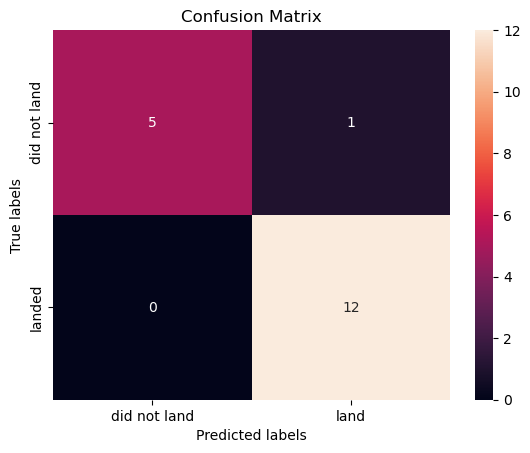

In [36]:
yhat=logreg_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

Examining the confusion matrix, we see that logistic regression can distinguish between the different classes.  We see that the problem is false positives.

Overview:

True Postive - 12 (True label is landed, Predicted label is also landed)

False Postive - 3 (True label is not landed, Predicted label is landed)


## TASK  6


Create a support vector machine object then  create a  <code>GridSearchCV</code> object  <code>svm_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [40]:
parameters = {'kernel':('linear', 'rbf','poly','rbf', 'sigmoid'),
              'C': np.logspace(-3, 3, 5),
              'gamma':np.logspace(-3, 3, 5)}
svm = SVC()
# Create the GridSearchCV object with 10-fold CV
svm_cv = GridSearchCV(svm, parameters, cv=10)

# Fit the object to the data (replace X, y with your dataset)
svm_cv.fit(X, Y)

GridSearchCV(cv=10, estimator=SVC(),
             param_grid={'C': array([1.00000000e-03, 3.16227766e-02, 1.00000000e+00, 3.16227766e+01,
       1.00000000e+03]),
                         'gamma': array([1.00000000e-03, 3.16227766e-02, 1.00000000e+00, 3.16227766e+01,
       1.00000000e+03]),
                         'kernel': ('linear', 'rbf', 'poly', 'rbf', 'sigmoid')})

In [41]:
print("tuned hpyerparameters :(best parameters) ",svm_cv.best_params_)
print("accuracy :",svm_cv.best_score_)
accuracy_all.append(svm_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'C': 1.0, 'gamma': 0.03162277660168379, 'kernel': 'sigmoid'}
accuracy : 0.8222222222222223


## TASK  7


Calculate the accuracy on the test data using the method <code>score</code>:


In [44]:
accuracy = svm_cv.score(X_test, Y_test)
print("Accuracy on test data:", accuracy)
accuracy_all_test.append(accuracy)

Accuracy on test data: 0.9444444444444444


We can plot the confusion matrix


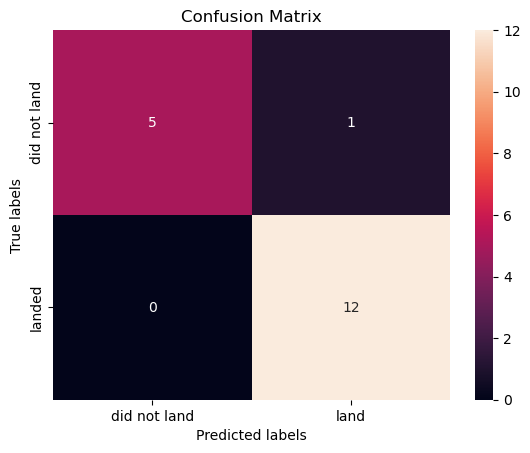

In [46]:
yhat=svm_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  8


Create a decision tree classifier object then  create a  <code>GridSearchCV</code> object  <code>tree_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [49]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

    parameters = {'criterion': ['gini', 'entropy'],
         'splitter': ['best', 'random'],
         'max_depth': [2*n for n in range(1,10)],
         'max_features': ['auto', 'sqrt'],
         'min_samples_leaf': [1, 2, 4],
         'min_samples_split': [2, 5, 10]}
    
    tree = DecisionTreeClassifier()
    
    tree_cv = GridSearchCV(tree, parameters, cv=10)
    
    # Fit the object to the data (replace X, y with your dataset)
    tree_cv.fit(X, Y)

In [50]:
print("tuned hpyerparameters :(best parameters) ",tree_cv.best_params_)
print("accuracy :",tree_cv.best_score_)
accuracy_all.append(tree_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'criterion': 'entropy', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'splitter': 'best'}
accuracy : 0.9


## TASK  9


Calculate the accuracy of tree_cv on the test data using the method <code>score</code>:


In [53]:
accuracy = tree_cv.score(X_test, Y_test)
print("Accuracy on test data:", accuracy)
accuracy_all_test.append(accuracy)

Accuracy on test data: 0.8888888888888888


We can plot the confusion matrix


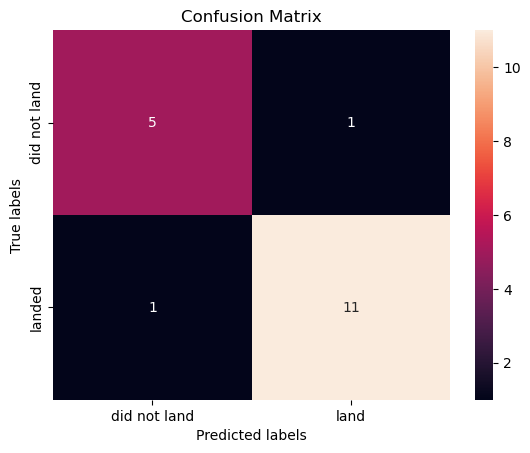

In [55]:
yhat = tree_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  10


Create a k nearest neighbors object then  create a  <code>GridSearchCV</code> object  <code>knn_cv</code> with cv = 10.  Fit the object to find the best parameters from the dictionary <code>parameters</code>.


In [58]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
              'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
              'p': [1,2]}

KNN = KNeighborsClassifier()

knn_cv = GridSearchCV(KNN, parameters, cv=10)

# Fit the object to the data (replace X, y with your dataset)
knn_cv.fit(X, Y)

GridSearchCV(cv=10, estimator=KNeighborsClassifier(),
             param_grid={'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
                         'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                         'p': [1, 2]})

In [59]:
print("tuned hpyerparameters :(best parameters) ",knn_cv.best_params_)
print("accuracy :",knn_cv.best_score_)
accuracy_all.append(knn_cv.best_score_)

tuned hpyerparameters :(best parameters)  {'algorithm': 'auto', 'n_neighbors': 5, 'p': 1}
accuracy : 0.8444444444444444


## TASK  11


Calculate the accuracy of knn_cv on the test data using the method <code>score</code>:


In [62]:
accuracy = knn_cv.score(X_test, Y_test)
print("Accuracy on test data:", accuracy)
accuracy_all_test.append(accuracy)

Accuracy on test data: 0.9444444444444444


We can plot the confusion matrix


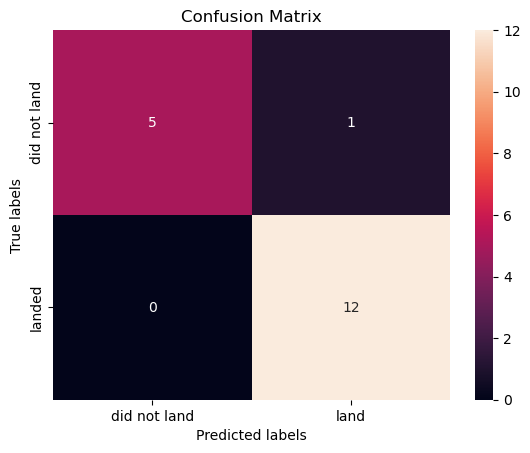

In [64]:
yhat = knn_cv.predict(X_test)
plot_confusion_matrix(Y_test,yhat)

## TASK  12


Find the method performs best:


In [67]:
print(accuracy_all_test)
print(accuracy_all)

[0.9444444444444444, 0.9444444444444444, 0.8888888888888888, 0.9444444444444444]
[0.8222222222222222, 0.8222222222222223, 0.9, 0.8444444444444444]


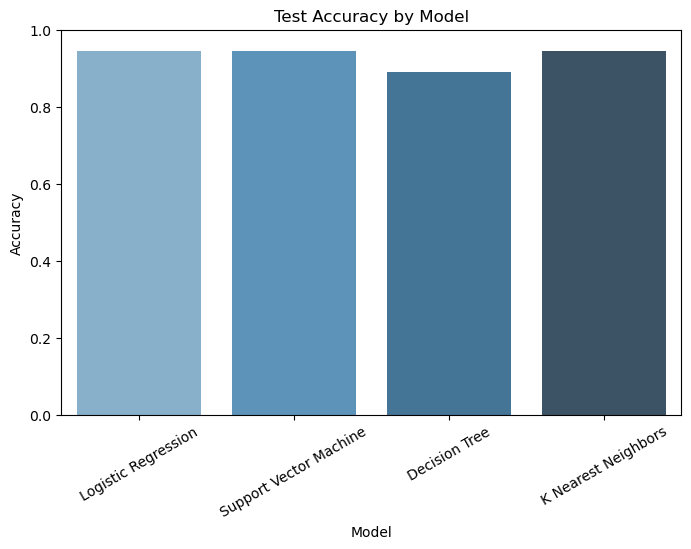

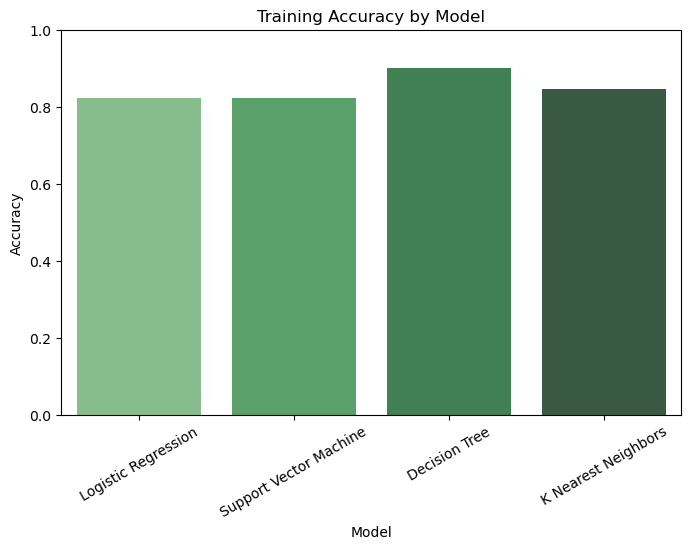

In [107]:
models = ["Logistic Regression", "Support Vector Machine", "Decision Tree", "K Nearest Neighbors"]

# Accuracy values
test_accuracy = [0.9444444444444444, 0.9444444444444444, 0.8888888888888888, 0.9444444444444444]
train_accuracy = [0.8222222222222222, 0.8222222222222223, 0.9, 0.8444444444444444]

# Create DataFrames
df_test = pd.DataFrame({"Model": models, "Accuracy": test_accuracy})
df_train = pd.DataFrame({"Model": models, "Accuracy": train_accuracy})

# Plot test accuracy
plt.figure(figsize=(8, 5))
sns.barplot(x="Model", y="Accuracy", data=df_test, palette="Blues_d")
plt.title("Test Accuracy by Model")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.show()

# Plot training accuracy
plt.figure(figsize=(8, 5))
sns.barplot(x="Model", y="Accuracy", data=df_train, palette="Greens_d")
plt.title("Training Accuracy by Model")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.show()

C:\Users\svein\AppData\Local\Temp\ipykernel_50140\2665561839.py:20: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 1)  # zoom in to relevant range


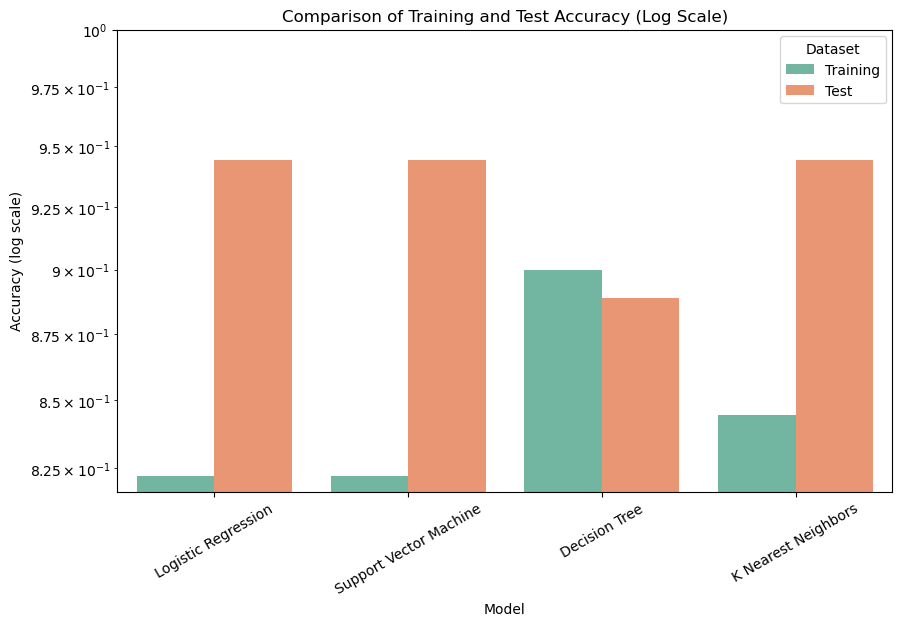

In [111]:
# Model names
models = ["Logistic Regression", "Support Vector Machine", "Decision Tree", "K Nearest Neighbors"]

# Accuracy values
test_accuracy = [0.9444444444444444, 0.9444444444444444, 0.8888888888888888, 0.9444444444444444]
train_accuracy = [0.8222222222222222, 0.8222222222222223, 0.9, 0.8444444444444444]

# Create a long-format DataFrame for grouped plotting
df = pd.DataFrame({
    "Model": models * 2,
    "Accuracy": train_accuracy + test_accuracy,
    "Dataset": ["Training"]*4 + ["Test"]*4
})

# Plot grouped bar chart
plt.figure(figsize=(10,6))
sns.barplot(x="Model", y="Accuracy", hue="Dataset", data=df, palette="Set2")
plt.yscale("log")  # logarithmic scale
plt.title("Comparison of Training and Test Accuracy (Log Scale)")
plt.ylim(0, 1)  # zoom in to relevant range
plt.xticks(rotation=30)
plt.ylabel("Accuracy (log scale)")
plt.show()

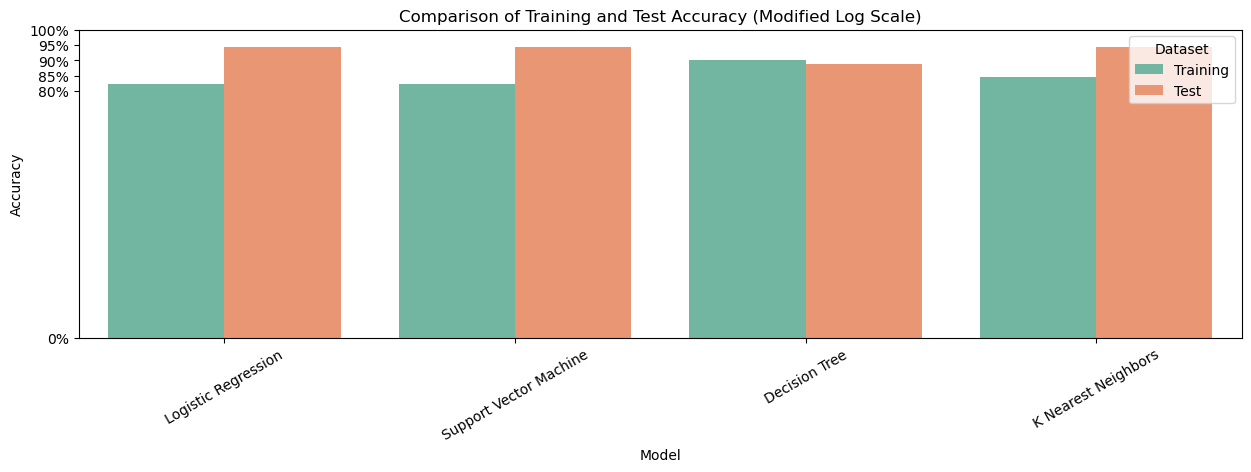

In [127]:
# Model names
models = ["Logistic Regression", "Support Vector Machine", "Decision Tree", "K Nearest Neighbors"]

# Accuracy values
test_accuracy = [0.9444444444444444, 0.9444444444444444, 0.8888888888888888, 0.9444444444444444]
train_accuracy = [0.8222222222222222, 0.8222222222222223, 0.9, 0.8444444444444444]

# Create long-format DataFrame
df = pd.DataFrame({
    "Model": models * 2,
    "Accuracy": train_accuracy + test_accuracy,
    "Dataset": ["Training"]*4 + ["Test"]*4
})

# Plot grouped bar chart with symlog scale
plt.figure(figsize=(15,4))
sns.barplot(x="Model", y="Accuracy", hue="Dataset", data=df, palette="Set2")

# plt.yscale("symlog", linthresh=1)  # linear below 0.01, log above
plt.ylim(0, 1)  # start y-axis from 0
plt.title("Comparison of Training and Test Accuracy (Modified Log Scale)")
plt.xticks(rotation=30)
plt.ylabel("Accuracy")
plt.yticks([0, 0.8, 0.85, 0.9, 0.95, 1], ["0%", "80%", "85%", "90%", "95%", "100%"])  # nicer labels
plt.legend(title="Dataset")
plt.show()

## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log--!>


<!--| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|--!>


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
